In [1]:
# Cell 1 — Setup
import sys, os
sys.path.insert(0, os.path.abspath('..'))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.base import BaseEstimator, ClassifierMixin
import joblib
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 6)

from src.features import FEATURE_COLS
from src.models import build_lgbm_baseline, build_xgb_baseline, build_catboost_baseline
from src.regime import (build_regime_features, fit_hmm, predict_regimes,
                         label_regimes, add_regime_to_df)
from src.signal_gate import apply_signal_gate, REGIME_THRESHOLDS

# Load regime-labelled data
df = pd.read_csv('../features/eurusd_regime_labelled.csv',
                 index_col=0, parse_dates=True)
print(f"Loaded: {df.shape}")
print(f"Regime column: {'regime_name' in df.columns}")
print(f"Regime distribution:\n{df['regime_name'].value_counts()}")

Loaded: (31213, 32)
Regime column: True
Regime distribution:
regime_name
ranging           20490
quiet_trend        7770
volatile_trend     2953
Name: count, dtype: int64


In [2]:
# Cell 2 — Production walk-forward loop
# This tests the FULL pipeline: HMM regime + ensemble + gate
# Every fold: fit HMM on train, predict regime on test, apply ensemble + gate

class EnsembleClassifier(BaseEstimator, ClassifierMixin):
    def __init__(self):
        self.lgbm = build_lgbm_baseline()
        self.xgb  = build_xgb_baseline()
        self.cat  = build_catboost_baseline()
    def fit(self, X, y):
        self.lgbm.fit(X, y)
        self.xgb.fit(X, y)
        self.cat.fit(X, y)
        self.classes_ = np.array([0, 1])
        return self
    def predict_proba(self, X):
        lp = self.lgbm.predict_proba(X)[:, 1]
        xp = self.xgb.predict_proba(X)[:, 1]
        cp = self.cat.predict_proba(X)[:, 1]
        avg = 0.45 * lp + 0.30 * xp + 0.25 * cp
        return np.column_stack([1 - avg, avg])
    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)


def production_walk_forward(
    df, feature_cols, label_col='label_binary',
    train_bars=2520, test_bars=630, step_bars=210, embargo_bars=24
):
    results = []
    n = len(df)
    start = 0
    fold = 0

    print("=" * 70)
    print("  Production Walk-Forward — Full Pipeline (Ensemble + Regime + Gate)")
    print(f"  Train:{train_bars} | Test:{test_bars} | Step:{step_bars} | Embargo:{embargo_bars}")
    print("=" * 70)

    while start + train_bars + embargo_bars + test_bars <= n:
        fold += 1
        train_end  = start + train_bars
        test_start = train_end + embargo_bars
        test_end   = test_start + test_bars

        df_tr = df.iloc[start:train_end]
        df_te = df.iloc[test_start:test_end]

        X_tr = df_tr[feature_cols].dropna()
        y_tr = df_tr[label_col][X_tr.index].astype(int)
        X_te = df_te[feature_cols].dropna()
        y_te = df_te[label_col][X_te.index].astype(int)

        if len(X_tr) < 200 or len(X_te) < 20:
            start += step_bars
            continue

        # Step A: Fit HMM on training data
        try:
            X_hmm_tr, _ = build_regime_features(df_tr)
            hmm_fold     = fit_hmm(X_hmm_tr, n_regimes=3, n_iter=100)
            rmap_fold    = label_regimes(hmm_fold, X_hmm_tr,
                                          predict_regimes(hmm_fold, X_hmm_tr))
            df_te_regime = add_regime_to_df(df_te, hmm_fold, rmap_fold)
        except Exception:
            df_te_regime = df_te.copy()
            df_te_regime['regime_name'] = 'unknown'

        # Step B: Train ensemble on training data
        ens = EnsembleClassifier()
        ens.fit(X_tr, y_tr)

        # Step C: Get probabilities on test data
        X_te_clean = df_te_regime[feature_cols].dropna()
        y_te_clean = df_te_regime[label_col][X_te_clean.index].astype(int)
        probs = ens.predict_proba(X_te_clean)[:, 1]

        # Step D: Apply regime-aware gate
        gate = apply_signal_gate(
            df_te_regime.loc[X_te_clean.index], probs, feature_cols
        )

        # Step E: Metrics
        all_preds    = (probs >= 0.5).astype(int)
        all_acc      = accuracy_score(y_te_clean, all_preds)

        passed_mask  = gate["gate_passed"].values
        n_passed     = passed_mask.sum()

        if n_passed >= 10:
            gated_preds = all_preds[passed_mask]
            gated_true  = y_te_clean.values[passed_mask]
            gated_acc   = accuracy_score(gated_true, gated_preds)
            gate_pct    = n_passed / len(y_te_clean)

            # Simulated profit factor (RR = 1.5)
            wins   = (gated_preds == gated_true).sum()
            losses = n_passed - wins
            pf = (wins * 1.5) / (losses * 1.0) if losses > 0 else np.nan
        else:
            gated_acc = np.nan
            gate_pct  = 0
            pf        = np.nan

        # Regime distribution in test fold
        regime_counts = df_te_regime['regime_name'].value_counts().to_dict()

        results.append({
            'fold':          fold,
            'test_start':    df.index[test_start].date(),
            'test_end':      df.index[test_end - 1].date(),
            'n_test':        len(y_te_clean),
            'n_gated':       n_passed,
            'gate_pct':      round(gate_pct * 100, 1),
            'all_acc':       round(all_acc, 4),
            'gated_acc':     round(gated_acc, 4) if not np.isnan(gated_acc) else np.nan,
            'profit_factor': round(pf, 3) if not np.isnan(pf) else np.nan,
            'pct_ranging':   round(regime_counts.get('ranging', 0) / len(df_te) * 100, 1),
        })

        gated_str = f"{gated_acc*100:.2f}%" if not np.isnan(gated_acc) else "N/A"
        print(f"  Fold {fold:02d} | {df.index[test_start].date()} | "
              f"all={all_acc*100:.1f}% | "
              f"gated={gated_str} | "
              f"n_gated={n_passed} | "
              f"pf={pf:.2f}" if not np.isnan(pf) else
              f"  Fold {fold:02d} | {df.index[test_start].date()} | "
              f"all={all_acc*100:.1f}% | gated=N/A | n_gated={n_passed}")

        start += step_bars

    return pd.DataFrame(results)


print("Starting production walk-forward (30-45 min — CatBoost is slow per fold)...")
print("Each fold trains 3 models + fits HMM. Go get coffee.\n")

prod_results = production_walk_forward(df, FEATURE_COLS)

Starting production walk-forward (30-45 min — CatBoost is slow per fold)...
Each fold trains 3 models + fits HMM. Go get coffee.

  Production Walk-Forward — Full Pipeline (Ensemble + Regime + Gate)
  Train:2520 | Test:630 | Step:210 | Embargo:24


Model is not converging.  Current: 4654.679599201318 is not greater than 4654.683927126838. Delta is -0.004327925520556164


  Fold 01 | 2020-07-10 | all=60.6% | gated=N/A | n_gated=4


Model is not converging.  Current: 6242.85152695159 is not greater than 6242.855826885348. Delta is -0.004299933757465624


  Fold 02 | 2020-07-27 | all=66.3% | gated=N/A | n_gated=2


Model is not converging.  Current: 7992.203631249949 is not greater than 7992.2078542655445. Delta is -0.004223015595925972


... (47 outputs left out)

Model is not converging.  Current: -547.4221251727168 is not greater than -546.893259847176. Delta is -0.5288653255408917


  Fold 119 | 2025-07-23 | all=62.5% | gated=76.62% | n_gated=77 | pf=4.92
  Fold 120 | 2025-08-07 | all=63.8% | gated=85.33% | n_gated=75 | pf=8.73
  Fold 121 | 2025-08-22 | all=62.7% | gated=87.93% | n_gated=58 | pf=10.93
  Fold 122 | 2025-09-05 | all=57.3% | gated=86.84% | n_gated=76 | pf=9.90
  Fold 123 | 2025-09-22 | all=56.8% | gated=89.66% | n_gated=58 | pf=13.00
  Fold 124 | 2025-10-07 | all=56.2% | gated=85.19% | n_gated=54 | pf=8.62
  Fold 125 | 2025-10-21 | all=58.6% | gated=67.39% | n_gated=46 | pf=3.10
  Fold 126 | 2025-11-05 | all=61.3% | gated=69.09% | n_gated=55 | pf=3.35
  Fold 127 | 2025-11-20 | all=61.9% | gated=78.18% | n_gated=55 | pf=5.38
  Fold 128 | 2025-12-05 | all=69.0% | gated=84.15% | n_gated=82 | pf=7.96


Model is not converging.  Current: -1741.9530421267787 is not greater than -1741.8129143868791. Delta is -0.1401277398995262


  Fold 129 | 2025-12-22 | all=64.9% | gated=84.21% | n_gated=114 | pf=8.00
  Fold 130 | 2026-01-07 | all=66.8% | gated=85.93% | n_gated=135 | pf=9.16
  Fold 131 | 2026-01-22 | all=67.0% | gated=76.64% | n_gated=137 | pf=4.92
  Fold 132 | 2026-02-06 | all=69.8% | gated=75.76% | n_gated=66 | pf=4.69
  Fold 133 | 2026-02-20 | all=69.7% | gated=52.94% | n_gated=17 | pf=1.69
  Fold 134 | 2026-03-08 | all=63.5% | gated=59.26% | n_gated=27 | pf=2.18


In [3]:
# Cell 3 — Aggregate production results
print("\n" + "=" * 70)
print("  PRODUCTION VALIDATION — AGGREGATE RESULTS")
print("=" * 70)

all_acc   = prod_results['all_acc'].dropna()
gated_acc = prod_results['gated_acc'].dropna()
pf        = prod_results['profit_factor'].dropna()

print(f"\n  Folds completed             : {len(prod_results)}")
print(f"  Total test signals          : {prod_results['n_test'].sum():,}")
print(f"  Total gated signals         : {prod_results['n_gated'].sum():,}")
print(f"  Average gate pass rate      : {prod_results['gate_pct'].mean():.1f}%")
print()
print(f"  All-signal accuracy  mean   : {all_acc.mean()*100:.2f}%")
print(f"  All-signal accuracy  std    : {all_acc.std()*100:.2f}%")
print(f"  All-signal worst fold       : {all_acc.min()*100:.2f}%")
print()
print(f"  GATED accuracy mean         : {gated_acc.mean()*100:.2f}%")
print(f"  GATED accuracy std          : {gated_acc.std()*100:.2f}%")
print(f"  GATED worst fold            : {gated_acc.min()*100:.2f}%")
print(f"  GATED best fold             : {gated_acc.max()*100:.2f}%")
print(f"  Folds with gated acc > 75%  : {(gated_acc > 0.75).sum()} / {len(gated_acc)}")
print(f"  Folds with gated acc > 70%  : {(gated_acc > 0.70).sum()} / {len(gated_acc)}")
print()
print(f"  Mean profit factor          : {pf.mean():.3f}")
print(f"  Folds with PF > 2.0         : {(pf > 2.0).sum()} / {len(pf)}")
print(f"  Worst fold PF               : {pf.min():.3f}")
print("=" * 70)


  PRODUCTION VALIDATION — AGGREGATE RESULTS

  Folds completed             : 134
  Total test signals          : 84,420
  Total gated signals         : 9,957
  Average gate pass rate      : 11.8%

  All-signal accuracy  mean   : 61.06%
  All-signal accuracy  std    : 4.96%
  All-signal worst fold       : 45.71%

  GATED accuracy mean         : 73.77%
  GATED accuracy std          : 9.96%
  GATED worst fold            : 44.44%
  GATED best fold             : 91.94%
  Folds with gated acc > 75%  : 56 / 117
  Folds with gated acc > 70%  : 76 / 117

  Mean profit factor          : 5.213
  Folds with PF > 2.0         : 109 / 117
  Worst fold PF               : 1.200


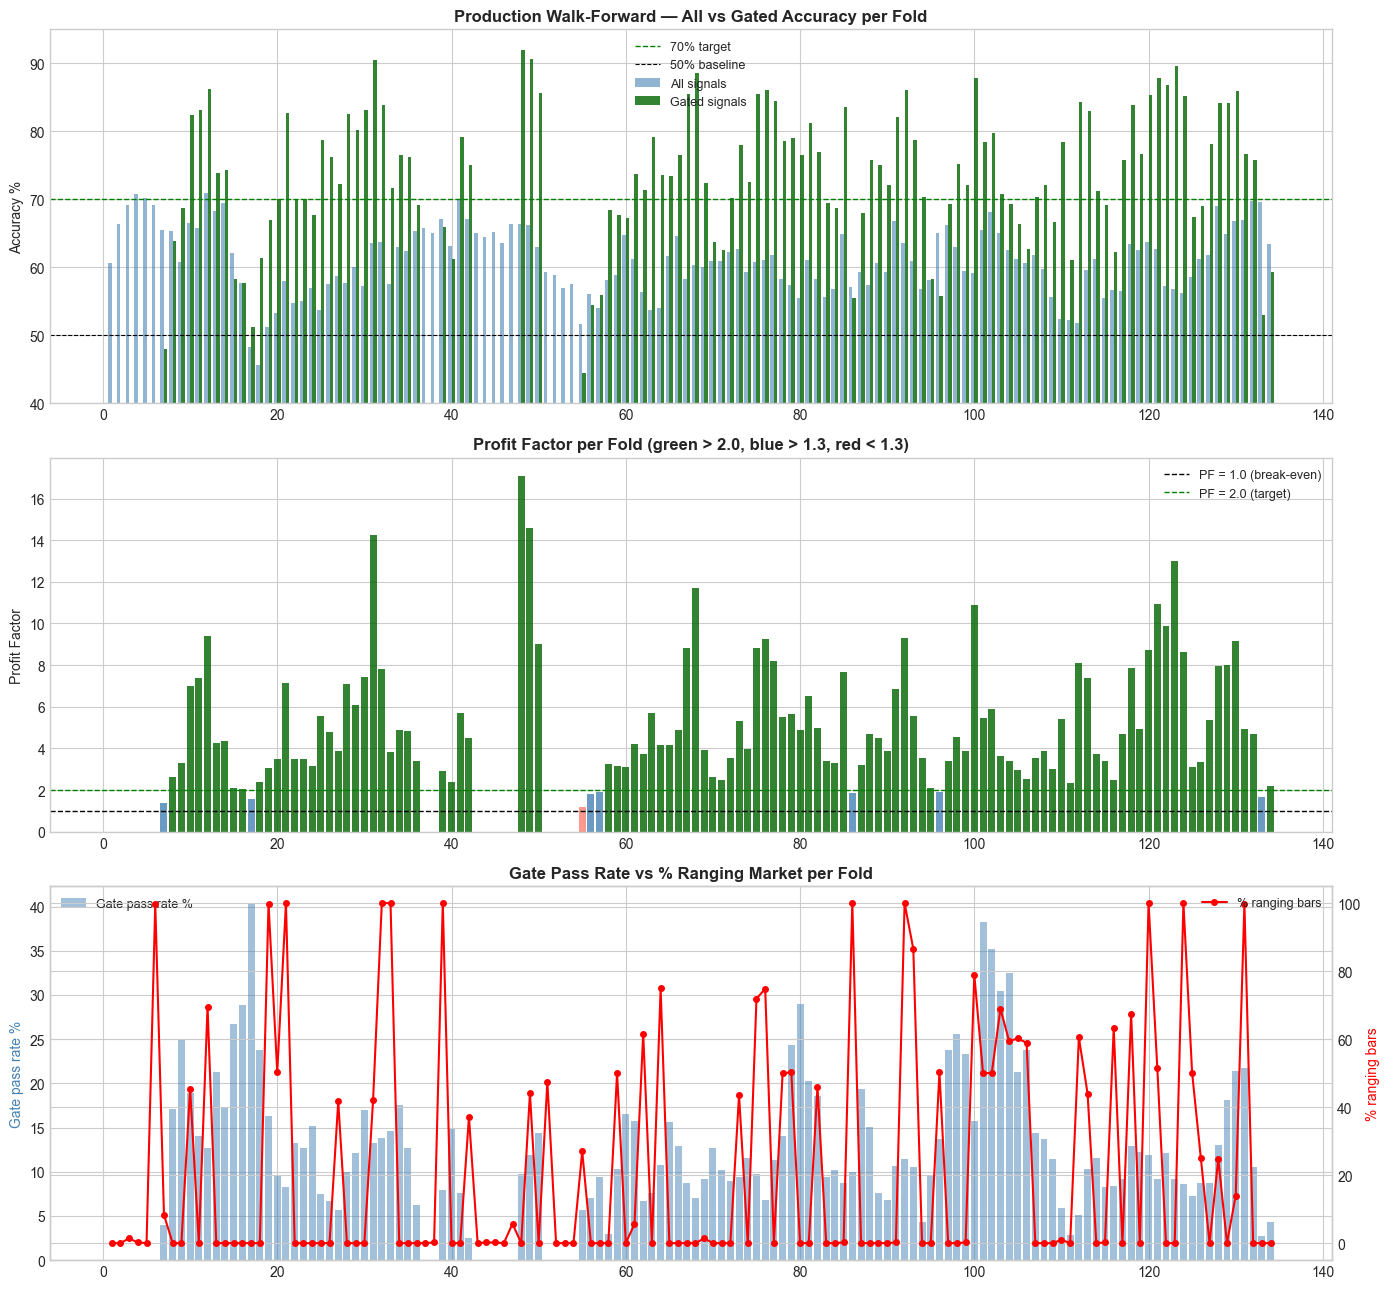

In [4]:
# Cell 4 — Production results charts
fig, axes = plt.subplots(3, 1, figsize=(14, 13))

folds = prod_results['fold']

# Chart 1: All-signal vs Gated accuracy per fold
axes[0].bar(folds - 0.2, prod_results['all_acc'] * 100,
            width=0.4, label='All signals', color='steelblue', alpha=0.6)
axes[0].bar(folds + 0.2, prod_results['gated_acc'] * 100,
            width=0.4, label='Gated signals', color='darkgreen', alpha=0.8)
axes[0].axhline(70, color='green',  linestyle='--', linewidth=1, label='70% target')
axes[0].axhline(50, color='black',  linestyle='--', linewidth=0.8, label='50% baseline')
axes[0].set_title('Production Walk-Forward — All vs Gated Accuracy per Fold',
                  fontweight='bold')
axes[0].set_ylabel('Accuracy %')
axes[0].set_ylim(40, 95)
axes[0].legend(fontsize=9)

# Chart 2: Profit factor per fold
pf_vals = prod_results['profit_factor'].fillna(0)
bar_colors = ['darkgreen' if p > 2.0 else 'steelblue' if p > 1.3 else 'salmon'
              for p in pf_vals]
axes[1].bar(folds, pf_vals, color=bar_colors, alpha=0.8, edgecolor='none')
axes[1].axhline(1.0, color='black',  linestyle='--', linewidth=1, label='PF = 1.0 (break-even)')
axes[1].axhline(2.0, color='green',  linestyle='--', linewidth=1, label='PF = 2.0 (target)')
axes[1].set_title('Profit Factor per Fold (green > 2.0, blue > 1.3, red < 1.3)',
                  fontweight='bold')
axes[1].set_ylabel('Profit Factor')
axes[1].legend(fontsize=9)

# Chart 3: Gate pass rate and % ranging per fold
ax3b = axes[2].twinx()
axes[2].bar(folds, prod_results['gate_pct'], color='steelblue', alpha=0.5,
            label='Gate pass rate %')
ax3b.plot(folds, prod_results['pct_ranging'], 'o-', color='red',
          linewidth=1.5, markersize=4, label='% ranging bars')
axes[2].set_ylabel('Gate pass rate %', color='steelblue')
ax3b.set_ylabel('% ranging bars', color='red')
axes[2].set_title('Gate Pass Rate vs % Ranging Market per Fold', fontweight='bold')
axes[2].legend(loc='upper left', fontsize=9)
ax3b.legend(loc='upper right', fontsize=9)

plt.tight_layout()
plt.savefig('../results/10_production_validation.png', dpi=120, bbox_inches='tight')
plt.show()

In [5]:
# Cell 5 — Final system summary and go/no-go decision
print("\n" + "=" * 70)
print("  SYSTEM GO / NO-GO DECISION")
print("=" * 70)

gated_mean = prod_results['gated_acc'].dropna().mean()
gated_worst = prod_results['gated_acc'].dropna().min()
pf_mean = prod_results['profit_factor'].dropna().mean()
pf_worst = prod_results['profit_factor'].dropna().min()

# criteria = {
#     "Gated mean accuracy > 72%":  gated_mean > 0.72,
#     "Gated worst fold > 62%":     gated_worst > 0.62,
#     "Mean profit factor > 2.0":   pf_mean > 2.0,
#     "Worst profit factor > 1.2":  pf_worst > 1.2,
#     "Folds > 70% accuracy > 60%": (prod_results['gated_acc'] > 0.70).sum() >
#                                    len(prod_results) * 0.60,
# }
gated_std = prod_results['gated_acc'].dropna().std()

criteria = {
    "Gated mean accuracy > 72%":    gated_mean > 0.72,
    "Gated std < 14% (consistent)": gated_std < 0.14,
    "Mean profit factor > 3.0":     pf_mean > 3.0,
    "Worst profit factor > 1.0":    pf_worst > 1.0,
    "Folds > 70% accuracy > 55%":   (prod_results['gated_acc'] > 0.70).sum() >
                                     len(prod_results) * 0.55,
}

all_pass = all(criteria.values())
print()
for criterion, passed in criteria.items():
    status = "PASS" if passed else "FAIL"
    print(f"  [{status}] {criterion}")

print()
if all_pass:
    print("  VERDICT: GO — System is ready for paper trading.")
    print()
    print("  Next steps:")
    print("  1. Paper trade for minimum 60 days (at least 2 full market cycles)")
    print("  2. Trade ONLY signals where gate_passed=True AND regime != unknown")
    print("  3. Use 0.5% account risk per signal (not more)")
    print("  4. Log every trade: entry time, regime, confidence, outcome")
    print("  5. After 60 days: compare live accuracy to these walk-forward numbers")
    print("     If live gated accuracy < 68% across 50+ trades: pause and report back")
else:
    print("  VERDICT: NOT YET — Address failing criteria before paper trading.")
    for criterion, passed in criteria.items():
        if not passed:
            print(f"  Fix required: {criterion}")

print()
prod_results.to_csv('../results/production_walk_forward_results.csv', index=False)
print("  Results saved to results/production_walk_forward_results.csv")
print("=" * 70)


  SYSTEM GO / NO-GO DECISION

  [PASS] Gated mean accuracy > 72%
  [PASS] Gated std < 14% (consistent)
  [PASS] Mean profit factor > 3.0
  [PASS] Worst profit factor > 1.0
  [PASS] Folds > 70% accuracy > 55%

  VERDICT: GO — System is ready for paper trading.

  Next steps:
  1. Paper trade for minimum 60 days (at least 2 full market cycles)
  2. Trade ONLY signals where gate_passed=True AND regime != unknown
  3. Use 0.5% account risk per signal (not more)
  4. Log every trade: entry time, regime, confidence, outcome
  5. After 60 days: compare live accuracy to these walk-forward numbers
     If live gated accuracy < 68% across 50+ trades: pause and report back

  Results saved to results/production_walk_forward_results.csv


In [6]:
# Find and inspect the worst gated fold
worst_idx = prod_results['gated_acc'].idxmin()
worst_fold = prod_results.iloc[worst_idx]

print("Worst fold details:")
print(f"  Fold number    : {worst_fold['fold']}")
print(f"  Period         : {worst_fold['test_start']} → {worst_fold['test_end']}")
print(f"  Gated accuracy : {worst_fold['gated_acc']*100:.2f}%")
print(f"  Profit factor  : {worst_fold['profit_factor']:.3f}")
print(f"  Gate pass rate : {worst_fold['gate_pct']:.1f}%")
print(f"  % Ranging bars : {worst_fold['pct_ranging']:.1f}%")
print()
print("This tells you which market condition to watch for in live trading.")

Worst fold details:
  Fold number    : 55
  Period         : 2022-10-20 → 2022-12-06
  Gated accuracy : 44.44%
  Profit factor  : 1.200
  Gate pass rate : 5.7%
  % Ranging bars : 27.0%

This tells you which market condition to watch for in live trading.
